In [1]:
!pip install hdbscan


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
import hdbscan

In [ ]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

In [4]:
df = pd.read_csv('Iris.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [5]:
X = df.iloc[:, 1:5].values
labels_true = pd.factorize(df['Species'])[0]

In [6]:
hdb = hdbscan.HDBSCAN().fit(X)

In [7]:
n_clusters = len(set(hdb.labels_)) - (1 if -1 in hdb.labels_ else 0)
n_noise = list(hdb.labels_).count(-1)
print(f"Jumlah cluster: {n_clusters}")
print(f"Jumlah noise: {n_noise} dari {len(X)} data")

Jumlah cluster: 2
Jumlah noise: 0 dari 150 data


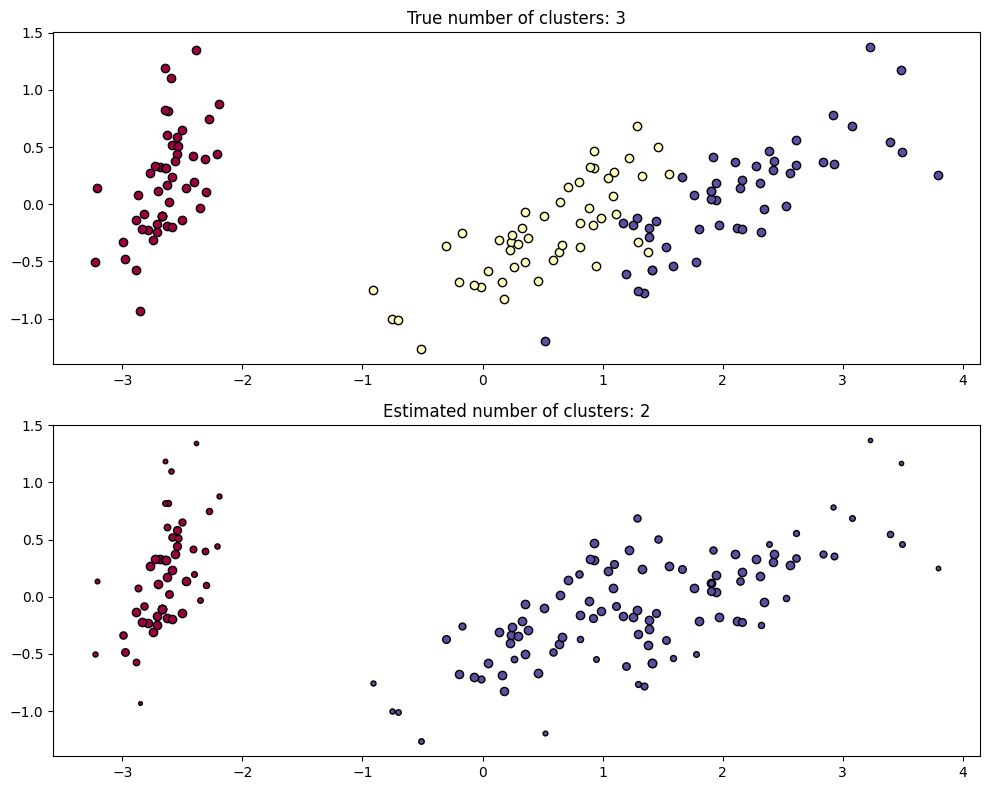

In [8]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
plot(X_pca, labels_true, ground_truth=True, ax=axes[0])
plot(X_pca, hdb.labels_, hdb.probabilities_, ax=axes[1])
plt.show()

In [9]:
print(pd.crosstab(df['Species'], hdb.labels_,
                  rownames=['Label asli'], colnames=['Label HDBSCAN']))

Label HDBSCAN     0   1
Label asli             
Iris-setosa      50   0
Iris-versicolor   0  50
Iris-virginica    0  50


HDBSCAN formed 2 clusters with no noise. Setosa was separated perfectly into its own cluster, while versicolor and virginica were merged into one cluster because the two species overlap in the feature space and their density is continuous. The result only partly matches the original labels, with 2 clusters found for 3 classes. This shows that HDBSCAN finds structure based on density and not the boundaries between species.